In [1]:
import pandas as pd

hotel = pd.read_csv(
    "../data/hotel_bookings_propre.csv",
    parse_dates=["reservation_status_date", "date_arrivee"],
)

print(hotel.shape)
print(hotel[["reservation_status_date", "date_arrivee"]].dtypes)

(86626, 33)
reservation_status_date    datetime64[us]
date_arrivee               datetime64[us]
dtype: object


In [2]:
taux_annulation = hotel.groupby("hotel")["is_canceled"].mean()
print(taux_annulation)

hotel
City Hotel      0.302002
Resort Hotel    0.237094
Name: is_canceled, dtype: float64


## Question 1 : quel hôtel a le plus fort taux d'annulation ?

Après nettoyage, le taux d'annulation est de **30,2 %** pour l'hôtel de ville
(`City Hotel`) contre **23,7 %** pour l'hôtel de villégiature
(`Resort Hotel`), soit environ 6,5 points d'écart.

**Limites :** la comparaison porte sur deux hôtels précis, elle ne permet pas de
généraliser à tous les hôtels de ville ou de villégiature. Elle montre une
différence, pas sa cause.

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

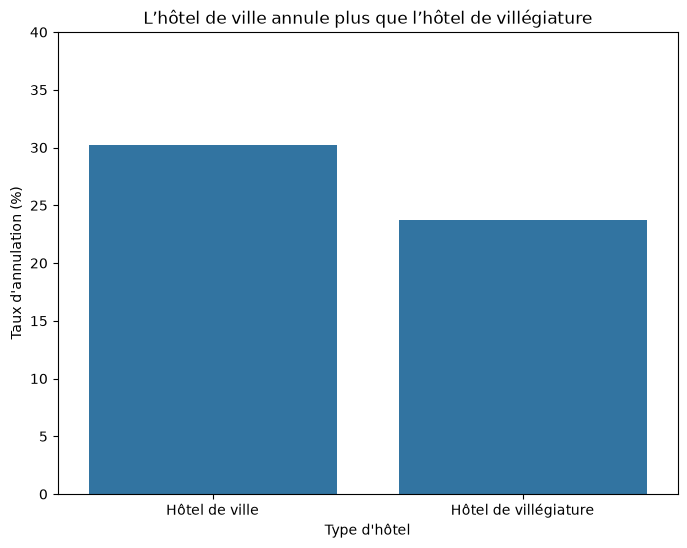

In [4]:
taux_pourcent = taux_annulation * 100 
fig , ax  = plt.subplots(figsize=(8, 6))
noms_francais = {"City Hotel": "Hôtel de ville", "Resort Hotel": "Hôtel de villégiature"}
noms_hotels = taux_pourcent.index.map(noms_francais)
sns.barplot(x=noms_hotels, y=taux_pourcent.values, ax=ax)
ax.set_title("L’hôtel de ville annule plus que l’hôtel de villégiature")
ax.set_xlabel("Type d'hôtel")
ax.set_ylabel("Taux d'annulation (%)")
ax.set_ylim(0, 40)
plt.show()
fig.savefig("../figures/q1_annulation_hotel.png", dpi=150, bbox_inches="tight")


**Conclusion Q1 :** l'hôtel de ville (*City Hotel*) a un taux d'annulation de 30,2 %, contre 23,7 % pour l'hôtel de villégiature (*Resort Hotel*), soit environ 6,5 points de plus. Un hôtel de ville est donc plus exposé aux annulations.

In [5]:
mois = hotel["date_arrivee"].dt.month
reservations_par_mois = hotel.groupby(mois).size()
print(reservations_par_mois)
print(hotel["date_arrivee"].min())
print(hotel["date_arrivee"].max())


date_arrivee
1      4638
2      6029
3      7438
4      7870
5      8295
6      7721
7      9987
8     11190
9      6658
10     6842
11     4914
12     5044
dtype: int64
2015-07-01 00:00:00
2017-08-31 00:00:00


In [6]:
annee = hotel["date_arrivee"].dt.year
nb_annees = annee.groupby(mois).nunique()
print(nb_annees)
reservations_par_an = reservations_par_mois / nb_annees
print(reservations_par_an.round(1).sort_values(ascending=False))


date_arrivee
1     2
2     2
3     2
4     2
5     2
6     2
7     3
8     3
9     2
10    2
11    2
12    2
Name: date_arrivee, dtype: int64
date_arrivee
5     4147.5
4     3935.0
6     3860.5
8     3730.0
3     3719.0
10    3421.0
7     3329.0
9     3329.0
2     3014.5
12    2522.0
11    2457.0
1     2319.0
dtype: float64


In [7]:
adr_par_mois = hotel.groupby(mois)["adr"].mean().round(1)
print(adr_par_mois.sort_values(ascending=False))



date_arrivee
8     151.7
7     136.5
6     120.4
9     112.6
5     111.9
4     104.1
10     91.4
12     82.8
3      81.7
2      75.5
11     73.8
1      70.9
Name: adr, dtype: float64


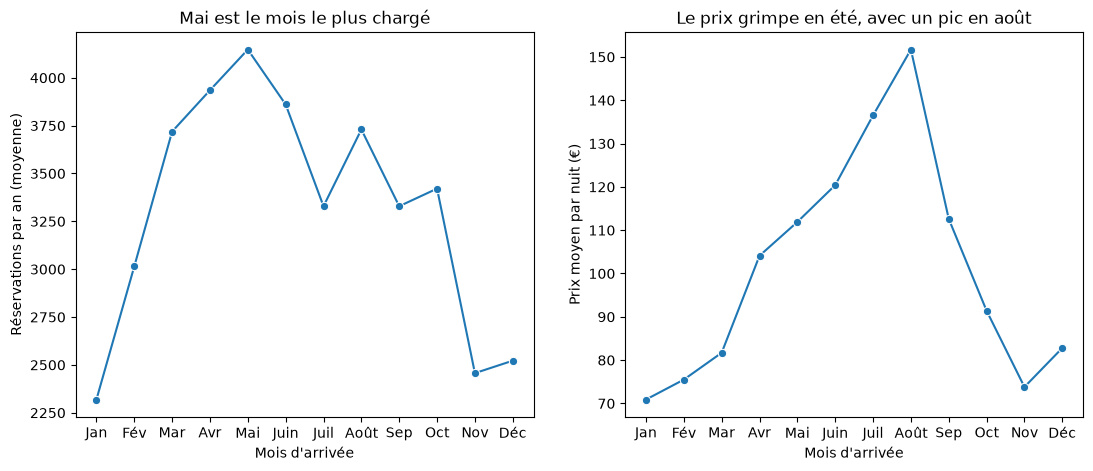

In [8]:
numero_vers_nom = {1: "Jan", 2: "Fév", 3: "Mar", 4: "Avr", 5: "Mai", 6: "Juin",
                   7: "Juil", 8: "Août", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Déc"}
noms_mois=reservations_par_an.index.map(numero_vers_nom)                   
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
sns.lineplot(x=noms_mois, y=reservations_par_an.values, marker="o", ax=ax1)
ax1.set_title("Mai est le mois le plus chargé")
ax1.set_xlabel("Mois d'arrivée")
ax1.set_ylabel("Réservations par an (moyenne)")

sns.lineplot(x=noms_mois, y=adr_par_mois.values, marker="o", ax=ax2)
ax2.set_title("Le prix grimpe en été, avec un pic en août")
ax2.set_xlabel("Mois d'arrivée")
ax2.set_ylabel("Prix moyen par nuit (€)")


fig.savefig("../figures/q2_saisonnalite.png", dpi=150, bbox_inches="tight")
plt.show()

## Question 2 : quels mois ont le plus de réservations et le prix moyen le plus élevé ?

Les données couvrent juillet 2015 à août 2017 : juillet et août apparaissent 3 fois, les autres mois 2 fois. Pour comparer équitablement, on calcule donc le nombre de réservations **moyen par année**.

**Conclusion Q2 :** mai est le mois le plus chargé (environ 4 150 réservations par an), suivi d'avril et de juin. Janvier est le plus calme (environ 2 300). Le prix moyen par nuit suit une autre logique : il monte en été et atteint son maximum en août (152 €), contre 71 € en janvier. Le mois le plus chargé n'est donc pas le plus cher.

In [9]:
print(hotel["lead_time"].describe())
bornes = [-1 , 7, 30, 90, 180, 365 , 720]
noms_tranches =  ["0-7 j", "8-30 j", "31-90 j", "91-180 j", "181-365 j", "> 365 j"]
hotel["tranche_delai"] =pd.cut(hotel["lead_time"],bins=bornes, labels=noms_tranches)
print(hotel["tranche_delai"].value_counts().sort_values(ascending=False))


count    86626.000000
mean        80.301769
std         86.074973
min          0.000000
25%         12.000000
50%         50.000000
75%        126.000000
max        709.000000
Name: lead_time, dtype: float64
tranche_delai
31-90 j      22633
91-180 j     18190
0-7 j        17848
8-30 j       16230
181-365 j    11164
> 365 j        561
Name: count, dtype: int64


In [10]:
taux_par_tranche = hotel.groupby("tranche_delai" , observed=True)["is_canceled"].mean() * 100
print(taux_par_tranche.round(1))

tranche_delai
0-7 j         8.5
8-30 j       25.5
31-90 j      32.1
91-180 j     35.1
181-365 j    39.8
> 365 j      41.0
Name: is_canceled, dtype: float64


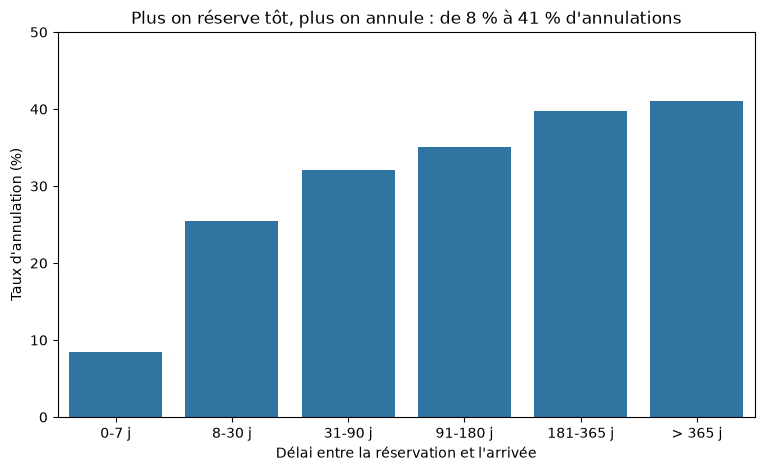

In [11]:
fig , ax = plt.subplots(figsize= (9,5))
sns.barplot(x=taux_par_tranche.index , y= taux_par_tranche.values,ax=ax)

ax.set_title("Plus on réserve tôt, plus on annule : de 8 % à 41 % d'annulations")
ax.set_xlabel("Délai entre la réservation et l'arrivée")
ax.set_ylabel("Taux d'annulation (%)")
ax.set_ylim(0, 50)
fig.savefig("../figures/q3_delai_annulation.png", dpi=150, bbox_inches="tight")
plt.show()

## Question 3 : un délai de réservation plus long augmente-t-il le taux d'annulation ?

Le délai (`lead_time`) va de 0 à 709 jours, avec une médiane de 50 jours. Pour le comparer, on le range en 6 tranches qui correspondent à des usages réels (dernière minute, mois, trimestre, semestre, année, plus d'un an).

**Conclusion Q3 :** oui, le taux d'annulation augmente à chaque tranche : de 8,5 % pour les réservations faites moins d'une semaine avant l'arrivée, à 41,0 % pour celles faites plus d'un an avant. Les données montrent un lien, mais pas sa cause : on peut supposer que plus on réserve tôt, plus les projets ont le temps de changer. **Limite :** la dernière tranche ne contient que 561 réservations, son taux est donc moins fiable.

In [12]:
prix_par_segment = hotel.groupby("market_segment")["adr"].mean().round(1)
print(prix_par_segment.sort_values(ascending=False))
print(hotel["market_segment"].value_counts())

market_segment
Online TA        118.9
Direct           118.1
Aviation         102.4
Offline TA/TO     82.2
Groups            75.6
Corporate         69.1
Complementary      3.1
Name: adr, dtype: float64
market_segment
Online TA        51281
Offline TA/TO    13748
Direct           11651
Groups            4891
Corporate         4151
Complementary      682
Aviation           222
Name: count, dtype: int64


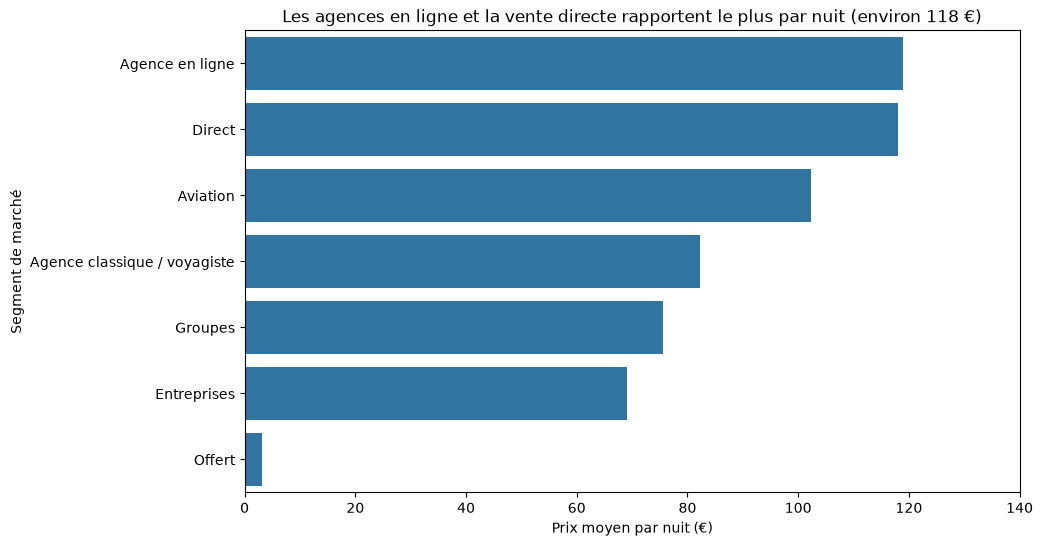

In [13]:
prix_trie = prix_par_segment.sort_values(ascending=False)
segment_en_francais = {"Online TA": "Agence en ligne", "Offline TA/TO": "Agence classique / voyagiste",
                        "Direct": "Direct", "Groups": "Groupes", "Corporate": "Entreprises",
                        "Complementary": "Offert", "Aviation": "Aviation"}

noms_segments = prix_trie.index.map(segment_en_francais)
fig , ax = plt.subplots(figsize=(10,6))
sns.barplot(x=prix_trie.values , y=noms_segments ,ax=ax)

ax.set_title("Les agences en ligne et la vente directe rapportent le plus par nuit (environ 118 €)")
ax.set_xlabel("Prix moyen par nuit (€)")
ax.set_ylabel("Segment de marché")
ax.set_xlim(0,140)
fig.savefig("../figures/q4_prix_segment.png", dpi=150, bbox_inches="tight")
plt.show()


## Question 4 : quel segment de marché rapporte le plus par nuit ?

On calcule le prix moyen par nuit (`adr`) de chaque segment de marché (canal par lequel la réservation est arrivée).

**Conclusion Q4 :** les agences en ligne (118,9 €) et la vente directe (118,1 €) rapportent le plus par nuit, avec un écart de moins de 1 € entre elles. Les agences en ligne pèsent beaucoup plus : 51 281 réservations (59 % du total), contre 11 651 en direct. Les entreprises (69,1 €) sont le segment payant le moins cher, et le segment « offert » (3,1 €) correspond à des nuits quasi gratuites. **Limite :** le segment Aviation ne compte que 222 réservations, son prix moyen (102,4 €) est donc moins fiable.

In [14]:
top_pays = hotel["country"].value_counts().head(10)
print(top_pays)


country
PRT    26855
GBR    10399
FRA     8813
ESP     7228
DEU     5385
ITA     3056
IRL     3014
BEL     2078
BRA     1988
NLD     1908
Name: count, dtype: int64


In [15]:
liste_top_pays = top_pays.index
hotel_top_pays = hotel[hotel["country"].isin(liste_top_pays)]
fidelite_par_pays = hotel_top_pays.groupby("country")["is_repeated_guest"].mean() * 100
print(fidelite_par_pays.round(1).sort_values(ascending=False))

country
PRT    9.9
ITA    1.2
ESP    1.1
IRL    1.0
NLD    1.0
GBR    0.9
FRA    0.8
BEL    0.8
BRA    0.7
DEU    0.4
Name: is_repeated_guest, dtype: float64


In [16]:
resume_pays = pd.DataFrame({
    "reservations": top_pays,
    "fidelite_pct": fidelite_par_pays.round(1),
}).reset_index()

print(resume_pays)
print(resume_pays.shape)

  country  reservations  fidelite_pct
0     BEL          2078           0.8
1     BRA          1988           0.7
2     DEU          5385           0.4
3     ESP          7228           1.1
4     FRA          8813           0.8
5     GBR         10399           0.9
6     IRL          3014           1.0
7     ITA          3056           1.2
8     NLD          1908           1.0
9     PRT         26855           9.9
(10, 3)


In [17]:
correspondance_pays= pd.DataFrame({
    "country": ["PRT", "GBR", "FRA", "ESP", "DEU", "ITA", "IRL", "BEL", "BRA", "NLD", "USA", "CHN"],
    "nom_pays": ["Portugal", "Royaume-Uni", "France", "Espagne", "Allemagne", "Italie", "Irlande",
                 "Belgique", "Brésil", "Pays-Bas", "États-Unis", "Chine"],
    "continent": ["Europe", "Europe", "Europe", "Europe", "Europe", "Europe", "Europe",
                  "Europe", "Amérique du Sud", "Europe", "Amérique du Nord", "Asie"],
})
resume_pays_complet = resume_pays.merge(correspondance_pays , on="country" , how="left")
print(resume_pays_complet.shape)
print(resume_pays_complet)

(10, 5)
  country  reservations  fidelite_pct     nom_pays        continent
0     BEL          2078           0.8     Belgique           Europe
1     BRA          1988           0.7       Brésil  Amérique du Sud
2     DEU          5385           0.4    Allemagne           Europe
3     ESP          7228           1.1      Espagne           Europe
4     FRA          8813           0.8       France           Europe
5     GBR         10399           0.9  Royaume-Uni           Europe
6     IRL          3014           1.0      Irlande           Europe
7     ITA          3056           1.2       Italie           Europe
8     NLD          1908           1.0     Pays-Bas           Europe
9     PRT         26855           9.9     Portugal           Europe


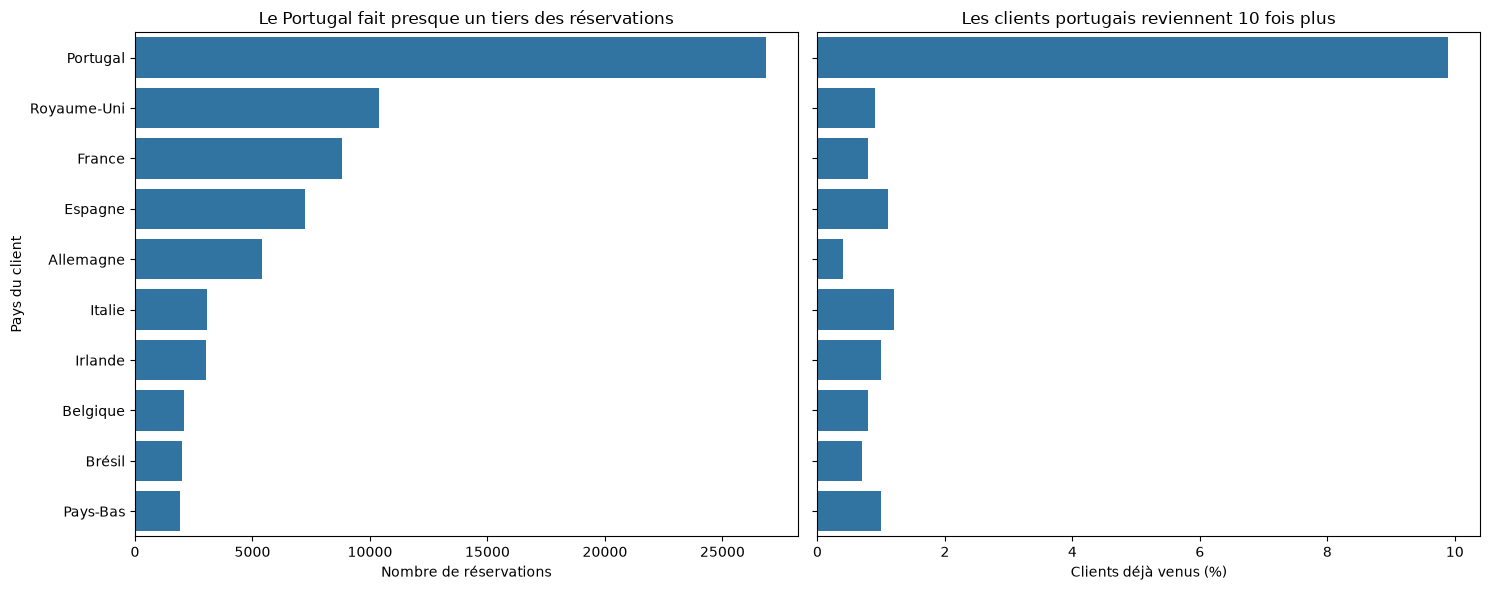

In [18]:

resume_trie = resume_pays_complet.sort_values("reservations", ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

sns.barplot(x=resume_trie["reservations"], y=resume_trie["nom_pays"], ax=ax1)
ax1.set_title("Le Portugal fait presque un tiers des réservations")
ax1.set_xlabel("Nombre de réservations")
ax1.set_ylabel("Pays du client")

sns.barplot(x=resume_trie["fidelite_pct"], y=resume_trie["nom_pays"], ax=ax2)
ax2.set_title("Les clients portugais reviennent 10 fois plus")
ax2.set_xlabel("Clients déjà venus (%)")

fig.tight_layout()
fig.savefig("../figures/q5_pays_fidelite.png", dpi=150, bbox_inches="tight")
plt.show()

## Question 5 : quels pays amènent le plus de clients, et sont-ils plus fidèles ?

On compte les réservations par pays d'origine du client et on garde les 10 premiers (environ 82 % des réservations). Les codes pays sont ensuite reliés, par une jointure sur la colonne `country`, à une petite table de correspondance (nom du pays et continent) écrite à la main. Contrôle de la jointure : 10 lignes avant, 10 lignes après, aucun pays sans continent.

**Conclusion Q5 :** le Portugal est le premier pays d'origine, avec 26 855 réservations (environ 31 % du total), loin devant le Royaume-Uni (10 399) et la France (8 813). Les clients portugais sont aussi nettement plus fidèles : 9,9 % sont déjà venus, contre 0,4 % à 1,2 % pour les autres pays du top 10. On peut supposer que cela s'explique par la proximité des hôtels, mais les données ne le montrent pas. **Limites :** seuls les 10 premiers pays sont étudiés, et la table de correspondance a été écrite à la main.